# Part B (02): Feature extraction
Input: `splits_part_b.csv` from notebook 01 (same split for every model).
Output: cached images + feature matrices in `../cache/` (gitignored).

Feature sets:
- **A. Raw pixels** (flattened) - baseline
- **B. Color histogram** (8x8x8 joint RGB bins) - banknotes differ a lot by color
- **C. PCA on raw pixels** - fit on **train only**

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from PIL import Image, ImageOps
from sklearn.decomposition import PCA

SEED = 12
IMG_SIZE = (64, 64)
SPLITS = Path("splits_part_b.csv")
CACHE = Path("../cache"); CACHE.mkdir(exist_ok=True)
CLASSES = ["5", "10", "20", "50", "100"]          
cls2id = {c: i for i, c in enumerate(CLASSES)}

## 1. Load the split and the images
`dtype={"label": str}` matters: otherwise pandas reads class names as integers.
`exif_transpose` fixes phone photos that are stored rotated.

In [2]:
splits = pd.read_csv(SPLITS, dtype={"label": str})
parts = {s: splits[splits["split"] == s].reset_index(drop=True) for s in ["train", "val", "test"]}
print({s: len(p) for s, p in parts.items()})

def load_uint8(frame):
    X = np.stack([
        np.asarray(ImageOps.exif_transpose(Image.open(p)).convert("RGB").resize(IMG_SIZE), dtype=np.uint8)
        for p in frame["path"]
    ])
    y = frame["label"].map(cls2id).to_numpy()
    return X, y

X_train, y_train = load_uint8(parts["train"])
X_val,   y_val   = load_uint8(parts["val"])
X_test,  y_test  = load_uint8(parts["test"])
print(X_train.shape, X_val.shape, X_test.shape, X_train.dtype)

np.savez_compressed(CACHE / "images_uint8.npz",
                    X_train=X_train, y_train=y_train, X_val=X_val, y_val=y_val,
                    X_test=X_test, y_test=y_test, classes=np.array(CLASSES))

{'train': 1362, 'val': 299, 'test': 294}
(1362, 64, 64, 3) (299, 64, 64, 3) (294, 64, 64, 3) uint8


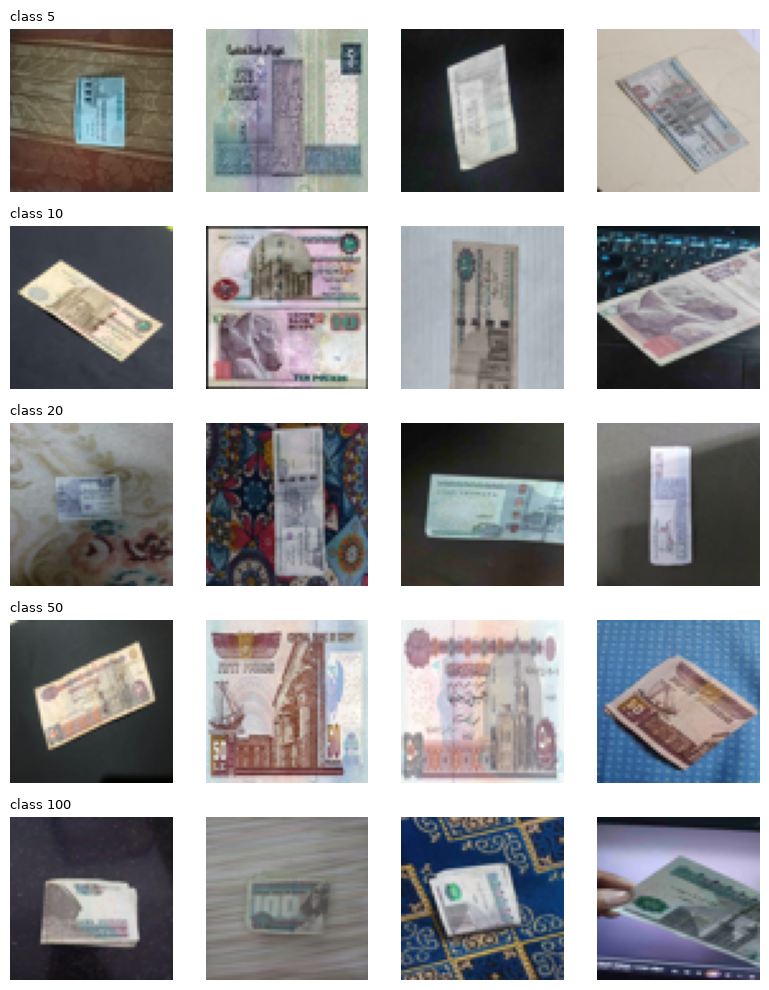

In [3]:
fig, axes = plt.subplots(len(CLASSES), 4, figsize=(8, 2 * len(CLASSES)))
for r, c in enumerate(CLASSES):
    idx = np.where(y_train == cls2id[c])[0][:4]
    for k, i in enumerate(idx):
        axes[r, k].imshow(X_train[i]); axes[r, k].axis("off")
    axes[r, 0].set_title(f"class {c}", loc="left", fontsize=9)
plt.tight_layout(); plt.show()

## 2. Feature set A: raw pixels
64 x 64 x 3 = 12288 features, scaled to [0, 1]. No statistics are learned, so no leakage.

In [4]:
def to_raw(X):
    return X.reshape(len(X), -1).astype(np.float32) / 255.0

R_train, R_val, R_test = to_raw(X_train), to_raw(X_val), to_raw(X_test)
print("raw pixels:", R_train.shape)

raw pixels: (1362, 12288)


## 3. Feature set B: color histogram
Each pixel is quantized to 8 levels per channel, so there are 8^3 = 512 color bins.
Each image becomes a normalized 512-dim vector (sum = 1), which removes the effect of image size.

In [5]:
BINS = 8

def color_hist(X):
    q = (X // (256 // BINS)).astype(np.int64)                
    idx = q[..., 0] * BINS * BINS + q[..., 1] * BINS + q[..., 2]
    H = np.zeros((len(X), BINS ** 3), dtype=np.float32)
    for i in range(len(X)):
        H[i] = np.bincount(idx[i].ravel(), minlength=BINS ** 3)
    return H / H.sum(axis=1, keepdims=True)

H_train, H_val, H_test = color_hist(X_train), color_hist(X_val), color_hist(X_test)
print("color histogram:", H_train.shape, "row sum:", H_train[0].sum())

color histogram: (1362, 512) row sum: 1.0


## 4. Feature set C: PCA on raw pixels
Fit on **train only**, then transform val and test with the same fitted object.
We keep enough components to explain 95% of the variance.

PCA features: (1362, 304) components kept: 304


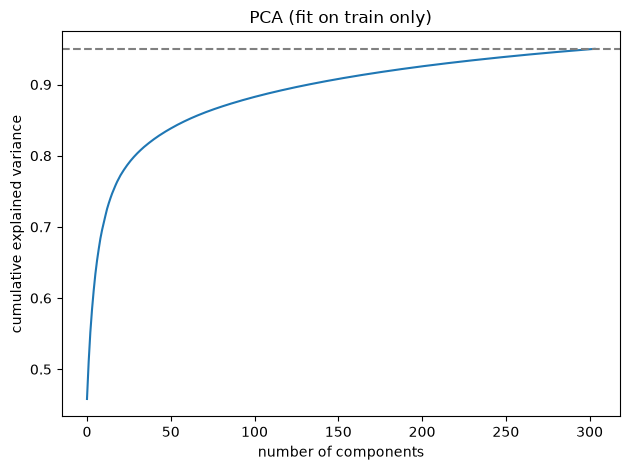

In [6]:
pca = PCA(n_components=0.95, svd_solver="full", random_state=SEED).fit(R_train)
P_train, P_val, P_test = pca.transform(R_train), pca.transform(R_val), pca.transform(R_test)
print("PCA features:", P_train.shape, "components kept:", pca.n_components_)

plt.plot(np.cumsum(pca.explained_variance_ratio_))
plt.axhline(0.95, ls="--", c="gray")
plt.xlabel("number of components"); plt.ylabel("cumulative explained variance")
plt.title("PCA (fit on train only)"); plt.tight_layout(); plt.show()

## 5. Summary table and save
The report needs: feature type, how many features, final dimension.

In [7]:
summary = pd.DataFrame({
    "feature set": ["A: raw pixels", "B: color histogram", "C: PCA(95%) on raw"],
    "dimension": [R_train.shape[1], H_train.shape[1], P_train.shape[1]],
})
print(summary.to_string(index=False))

np.savez_compressed(CACHE / "features.npz",
                    H_train=H_train, H_val=H_val, H_test=H_test,
                    P_train=P_train, P_val=P_val, P_test=P_test,
                    y_train=y_train, y_val=y_val, y_test=y_test)
joblib.dump(pca, CACHE / "pca.joblib")

       feature set  dimension
     A: raw pixels      12288
B: color histogram        512
C: PCA(95%) on raw        304


['../cache/pca.joblib']